In [73]:
#HOUSE PRICE PREDICTION DATASET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df=pd.read_csv(r"C:\Users\gkpmt\Downloads\archive (1)\House Price Prediction Dataset.csv")
print(df)

        Id  Area  Bedrooms  Bathrooms  Floors  YearBuilt  Location  Condition  \
0        1  1360         5          4       3       1970  Downtown  Excellent   
1        2  4272         5          4       3       1958  Downtown  Excellent   
2        3  3592         2          2       3       1938  Downtown       Good   
3        4   966         4          2       2       1902  Suburban       Fair   
4        5  4926         1          4       2       1975  Downtown       Fair   
...    ...   ...       ...        ...     ...        ...       ...        ...   
1995  1996  4994         5          4       3       1923  Suburban       Poor   
1996  1997  3046         5          2       1       2019  Suburban       Poor   
1997  1998  1062         5          1       2       1903     Rural       Poor   
1998  1999  4062         3          1       2       1936     Urban  Excellent   
1999  2000  2989         5          1       3       1903  Suburban       Fair   

     Garage   Price  
0    

In [75]:
#using df operations 
#shows first five elements
df.head()  

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [77]:
df.tail()  #shows last 5 elements in the dataframe

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
1995,1996,4994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,3046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,4062,3,1,2,1936,Urban,Excellent,Yes,161119
1999,2000,2989,5,1,3,1903,Suburban,Fair,No,482525


In [79]:
df["Area"] = pd.to_datetime(df["Area"])

In [81]:
df

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1970-01-01 00:00:00.000001360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,1970-01-01 00:00:00.000004272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,1970-01-01 00:00:00.000003592,2,2,3,1938,Downtown,Good,No,266746
3,4,1970-01-01 00:00:00.000000966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,1970-01-01 00:00:00.000004926,1,4,2,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...,...,...
1995,1996,1970-01-01 00:00:00.000004994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,1970-01-01 00:00:00.000003046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1970-01-01 00:00:00.000001062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,1970-01-01 00:00:00.000004062,3,1,2,1936,Urban,Excellent,Yes,161119


In [83]:
#shows the stastical configration of the dataframe
df.describe()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,1970-01-01 00:00:00.000002786,3.003500,2.55250,1.993500,1961.446000,537676.855000
min,1.000000,1970-01-01 00:00:00.000000501,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1970-01-01 00:00:00.000001653,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,1970-01-01 00:00:00.000002833,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,1970-01-01 00:00:00.000003887,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,1970-01-01 00:00:00.000004999,5.000000,4.00000,3.000000,2023.000000,999656.000000
std,577.494589,NaN,1.424606,1.10899,0.809188,35.926695,276428.845719


In [85]:
#used to describe the data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Id         2000 non-null   int64         
 1   Area       2000 non-null   datetime64[ns]
 2   Bedrooms   2000 non-null   int64         
 3   Bathrooms  2000 non-null   int64         
 4   Floors     2000 non-null   int64         
 5   YearBuilt  2000 non-null   int64         
 6   Location   2000 non-null   object        
 7   Condition  2000 non-null   object        
 8   Garage     2000 non-null   object        
 9   Price      2000 non-null   int64         
dtypes: datetime64[ns](1), int64(6), object(3)
memory usage: 156.4+ KB


In [87]:
#checking for the misssing values
print(df.isnull().sum())  

Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64


In [89]:
#checcking for the duplicate values 
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
1995    False
1996    False
1997    False
1998    False
1999    False
Length: 2000, dtype: bool

In [91]:
#removing the duplicate value in the data frame
print(df.duplicated().sum())  # Count duplicates
df.drop_duplicates(inplace=True)  # Remove duplicates

0


In [93]:
# Strip spaces and remove any unwanted characters
df.columns = df.columns.str.strip()
df

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1970-01-01 00:00:00.000001360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,1970-01-01 00:00:00.000004272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,1970-01-01 00:00:00.000003592,2,2,3,1938,Downtown,Good,No,266746
3,4,1970-01-01 00:00:00.000000966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,1970-01-01 00:00:00.000004926,1,4,2,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...,...,...
1995,1996,1970-01-01 00:00:00.000004994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,1970-01-01 00:00:00.000003046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1970-01-01 00:00:00.000001062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,1970-01-01 00:00:00.000004062,3,1,2,1936,Urban,Excellent,Yes,161119


In [95]:
# Check column data types
print(df.dtypes) 

Id                    int64
Area         datetime64[ns]
Bedrooms              int64
Bathrooms             int64
Floors                int64
YearBuilt             int64
Location             object
Condition            object
Garage               object
Price                 int64
dtype: object


In [97]:
data=pd.read_csv(r"C:\Users\gkpmt\Downloads\archive (1)\House Price Prediction Dataset.csv")

# Strip spaces and remove any unwanted characters
data.columns = data.columns.str.strip()

print(data.columns)

Index(['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt',
       'Location', 'Condition', 'Garage', 'Price'],
      dtype='object')


In [99]:
df.columns = df.columns.str.strip()
df

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1970-01-01 00:00:00.000001360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,1970-01-01 00:00:00.000004272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,1970-01-01 00:00:00.000003592,2,2,3,1938,Downtown,Good,No,266746
3,4,1970-01-01 00:00:00.000000966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,1970-01-01 00:00:00.000004926,1,4,2,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...,...,...
1995,1996,1970-01-01 00:00:00.000004994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,1970-01-01 00:00:00.000003046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1970-01-01 00:00:00.000001062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,1970-01-01 00:00:00.000004062,3,1,2,1936,Urban,Excellent,Yes,161119


In [101]:
df["Price"] = df["Price"].astype(int)
df

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1970-01-01 00:00:00.000001360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,1970-01-01 00:00:00.000004272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,1970-01-01 00:00:00.000003592,2,2,3,1938,Downtown,Good,No,266746
3,4,1970-01-01 00:00:00.000000966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,1970-01-01 00:00:00.000004926,1,4,2,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...,...,...
1995,1996,1970-01-01 00:00:00.000004994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,1970-01-01 00:00:00.000003046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1970-01-01 00:00:00.000001062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,1970-01-01 00:00:00.000004062,3,1,2,1936,Urban,Excellent,Yes,161119


In [103]:
df.columns = df.columns.str.strip()
df

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1970-01-01 00:00:00.000001360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,1970-01-01 00:00:00.000004272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,1970-01-01 00:00:00.000003592,2,2,3,1938,Downtown,Good,No,266746
3,4,1970-01-01 00:00:00.000000966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,1970-01-01 00:00:00.000004926,1,4,2,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...,...,...
1995,1996,1970-01-01 00:00:00.000004994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,1970-01-01 00:00:00.000003046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1970-01-01 00:00:00.000001062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,1970-01-01 00:00:00.000004062,3,1,2,1936,Urban,Excellent,Yes,161119


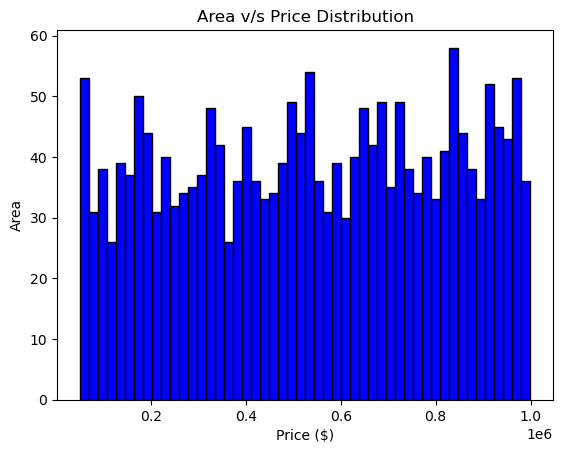

In [105]:
#plots!!
import matplotlib.pyplot as plt
df=pd.read_csv(r"C:\Users\gkpmt\Downloads\archive (1)\House Price Prediction Dataset.csv")


plt.hist(df['Price'], bins=50, color='blue', edgecolor='black')
plt.xlabel("Price ($)")
plt.ylabel("Area")
plt.title("Area v/s Price Distribution")
plt.show()


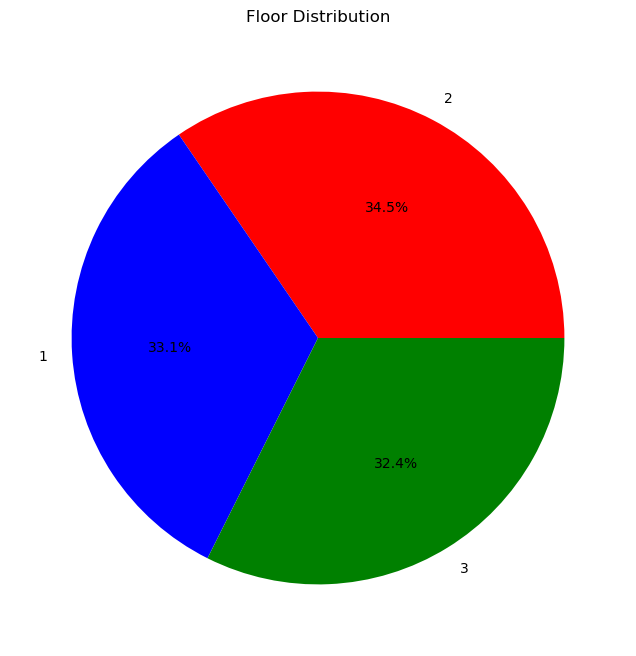

In [107]:
#pie chart
area_counting = df['Floors'].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(area_counting, labels=area_counting.index, autopct='%1.1f%%', colors=['red', 'blue', 'green'])
plt.title("Floor Distribution")
plt.show()

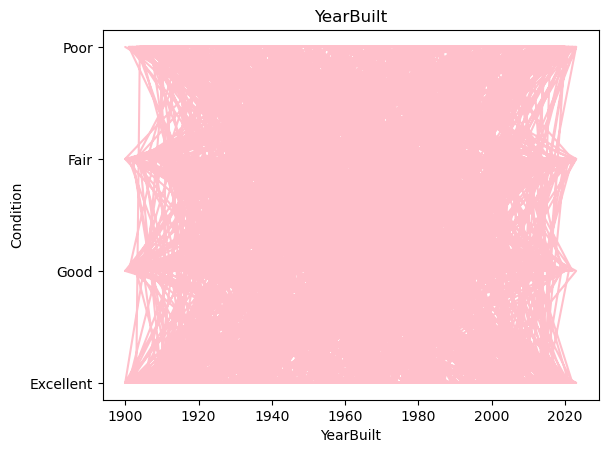

In [109]:
plt.plot(df["YearBuilt"], df["Condition"], color="pink")

plt.xlabel("YearBuilt")
plt.ylabel("Condition")
plt.title("YearBuilt")
plt.show()


# Add grid line

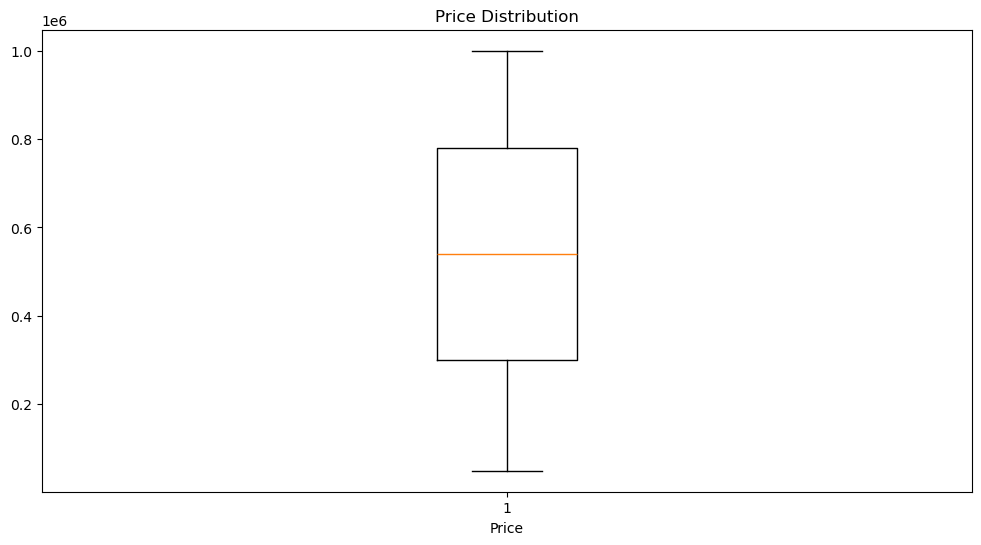

In [111]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['Price'])
plt.xlabel("Price")
plt.title("Price Distribution")
plt.show()


In [113]:
print(df.shape)

(2000, 10)


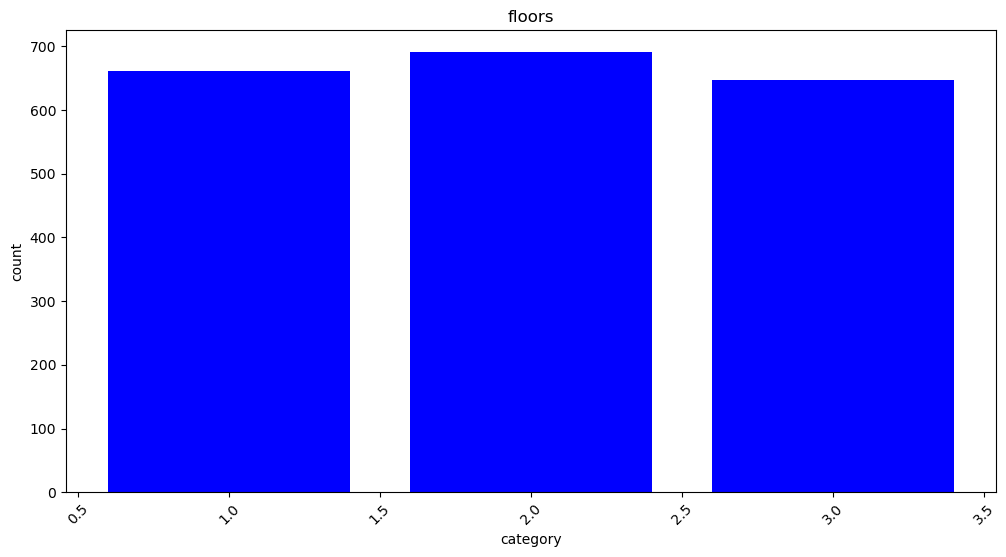

In [115]:
import matplotlib.pyplot as plt

top_categories = df["Floors"].value_counts().nlargest(10)
plt.figure(figsize=(12, 6))
plt.bar(top_categories.index, top_categories.values, color='blue')
plt.xticks(rotation=45)
plt.xlabel("category")
plt.ylabel("count")
plt.title("floors")
plt.show()


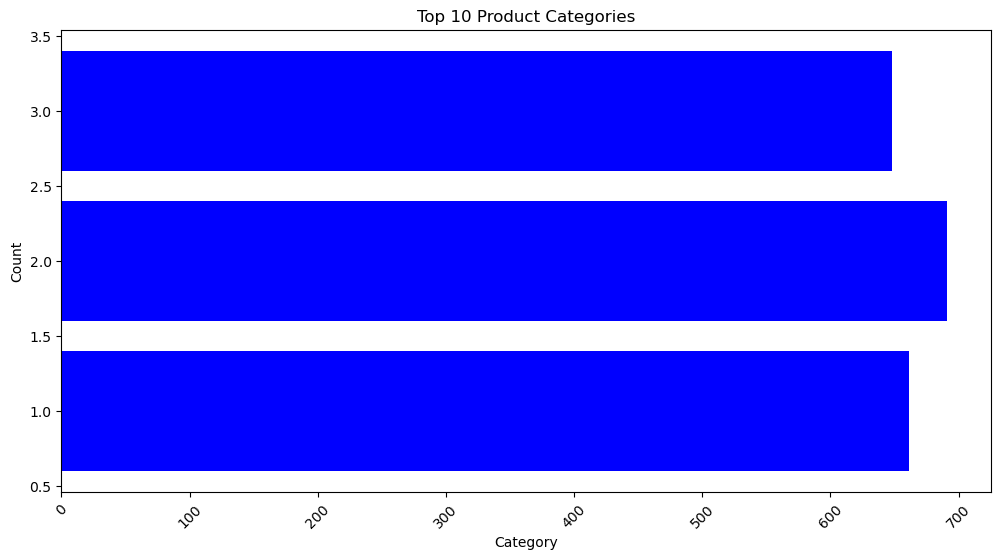

In [117]:
import matplotlib.pyplot as plt

#this Count the number of products in each category and select the top 10
floors_count = df['Floors'].value_counts().nlargest(10)



plt.figure(figsize=(12, 6))
plt.barh(floors_count.index, floors_count.values, color='blue')
plt.xticks(rotation=45)
plt.xlabel("Category")
plt.ylabel("Count")
plt.title("Top 10 Product Categories")
plt.show()


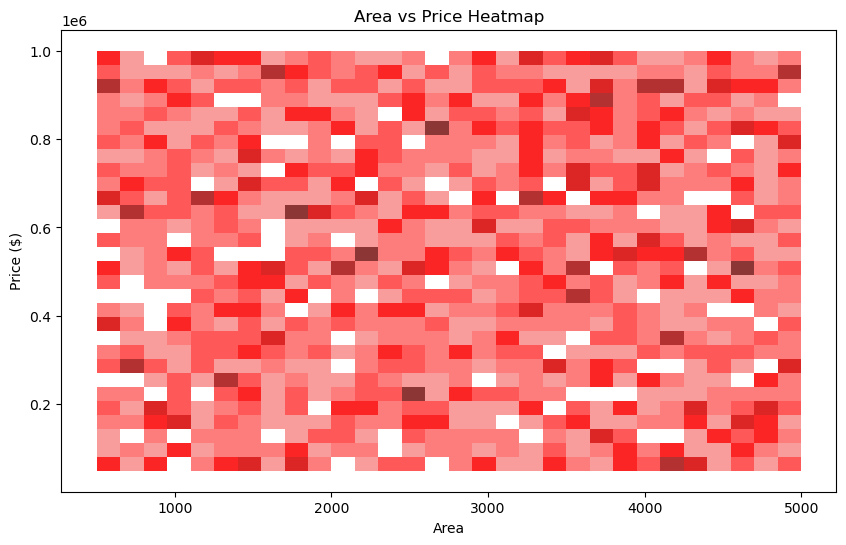

In [119]:
#Areq vs Price Heatmap
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="Area", y="Price", bins=30,color ="red" )
plt.title("Area vs Price Heatmap")
plt.xlabel("Area")
plt.ylabel("Price ($)")
plt.show()


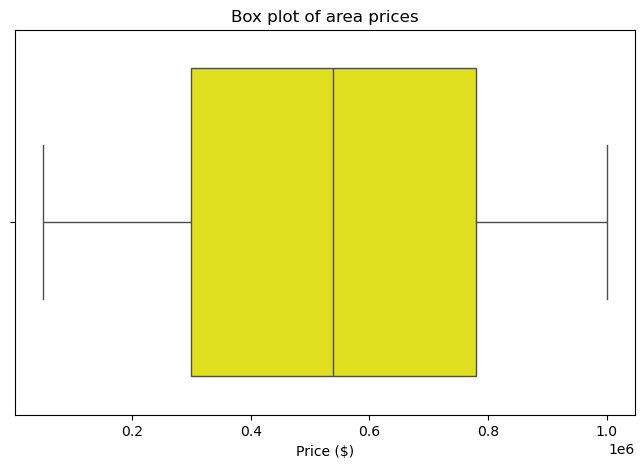

In [121]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Price"], color="yellow")
plt.title("Box plot of area prices")
plt.xlabel("Price ($)")
plt.show()


In [123]:
Q1 = df["Price"].quantile(0.25)  # First quartile (25th percentile)
Q3 = df["Price"].quantile(0.75)  # Third quartile (75th percentile)
IQR = Q3 - Q1                      # Interquartile Range

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["Price"] < lower_bound) | (df["Price"] > upper_bound)]
print("Outliers in Price Column:\n", outliers)


Outliers in Price Column:
 Empty DataFrame
Columns: [Id, Area, Bedrooms, Bathrooms, Floors, YearBuilt, Location, Condition, Garage, Price]
Index: []


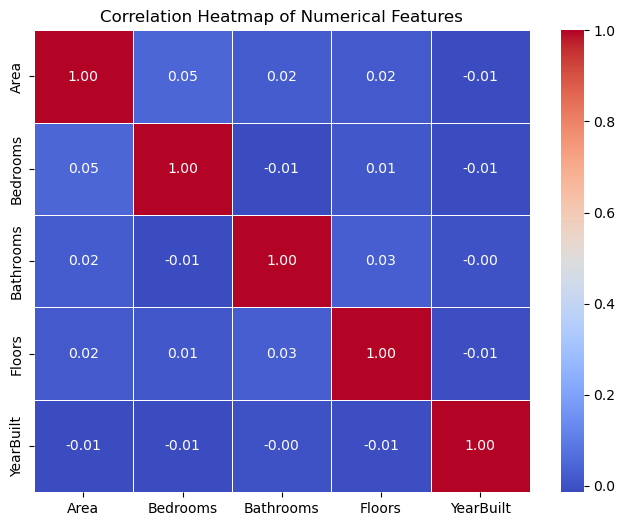

In [125]:
import matplotlib.pyplot as plt
import seaborn as sns

# Compute correlation matrix
correlation_matrix = df[["Area","Bedrooms","Bathrooms","Floors","YearBuilt"]].corr()

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()


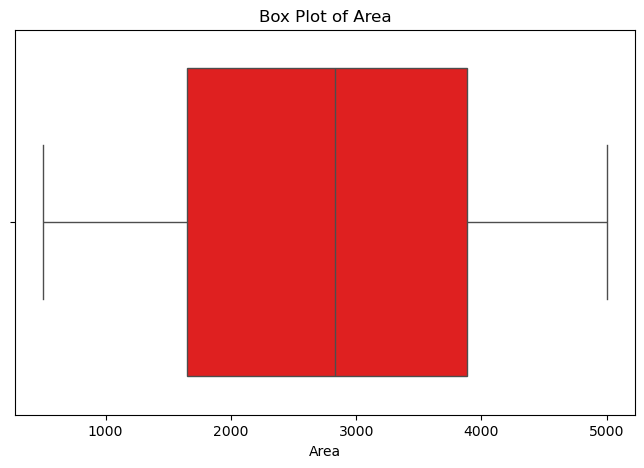

In [127]:
#box plot with area
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Area"], color="red")
plt.title("Box Plot of Area")
plt.xlabel("Area")
plt.show()

In [129]:
df.describe().T   #transpose function is used to make rows to colums and columns to rows

,count,mean,std,min,25%,50%,75%,max
Id,2000.0,1000.5000,577.494589,1.0,500.75,1000.5,1500.25,2000.0
Area,2000.0,2786.2095,1295.146799,501.0,1653.00,2833.0,3887.50,4999.0
Bedrooms,2000.0,3.0035,1.424606,1.0,2.00,3.0,4.00,5.0
Bathrooms,2000.0,2.5525,1.108990,1.0,2.00,3.0,4.00,4.0
Floors,2000.0,1.9935,0.809188,1.0,1.00,2.0,3.00,3.0
YearBuilt,2000.0,1961.4460,35.926695,1900.0,1930.00,1961.0,1993.00,2023.0
Price,2000.0,537676.8550,276428.845719,50005.0,300098.00,539254.0,780086.00,999656.0


In [131]:
import pandas as pd
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor 
from sklearn.metrics import mean_squared_error, r2_score

#Load your dataset

df=pd.read_csv(r"C:\Users\gkpmt\Downloads\archive (1)\House Price Prediction Dataset.csv")
df["Area"] = pd.to_datetime(df["Area"])
df["YearBuilt"]=(pd.Timestamp.now()-df["Area"]).dt.days
x=df[['Bedrooms','Bathrooms','Floors','YearBuilt']]
y=df['Area']

In [133]:
x

,Bedrooms,Bathrooms,Floors,YearBuilt
0,5,4,3,20198
1,5,4,3,20198
2,2,2,3,20198
3,4,2,2,20198
4,1,4,2,20198
...,...,...,...,...
1995,5,4,3,20198
1996,5,2,1,20198
1997,5,1,2,20198
1998,3,1,2,20198


In [135]:
y

0      1970-01-01 00:00:00.000001360
1      1970-01-01 00:00:00.000004272
2      1970-01-01 00:00:00.000003592
3      1970-01-01 00:00:00.000000966
4      1970-01-01 00:00:00.000004926
                    ...             
1995   1970-01-01 00:00:00.000004994
1996   1970-01-01 00:00:00.000003046
1997   1970-01-01 00:00:00.000001062
1998   1970-01-01 00:00:00.000004062
1999   1970-01-01 00:00:00.000002989
Name: Area, Length: 2000, dtype: datetime64[ns]

In [137]:
#spilt the data
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

In [139]:
#train the model
model=LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

In [141]:
y_pred=model.predict(x_test)

In [143]:
y_pred

array([2733.23707412, 2662.28759564, 2662.28759564, 2804.21888142,
       2733.23707412, 2697.9288606 , 2733.53779675, 2768.30922264,
       2803.93432319, 2733.25323853, 2768.86217468, 2839.55942375,
       2769.1467329 , 2946.13400279, 2839.54325934, 2732.98484471,
       2732.98484471, 2910.50890223, 2768.57761646, 2733.52163235,
       2732.70028649, 2768.86217468, 2804.21888142, 2732.96868031,
       2697.9288606 , 2768.86217468, 2804.21888142, 2839.29102993,
       2697.35974416, 2875.45291812, 2768.86217468, 2662.28759564,
       2874.89996608, 2839.54325934, 2875.1683599 , 2768.32538704,
       2733.52163235, 2768.32538704, 2768.60994527, 2840.11237579,
       2768.89450349, 2875.1683599 , 2803.66592938, 2697.64430238,
       2769.1467329 , 2803.93432319, 2910.52506664, 2732.98484471,
       2839.27486553, 2910.79346046, 2662.01920182, 2803.9504876 ,
       2804.20271701, 2768.04082882, 2768.32538704, 2803.64976497,
       2768.59378086, 2874.91613049, 2733.25323853, 2733.26940

In [149]:
#DATSET FOR E-COMMERECE
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
df=pd.read_csv(r"C:\Users\gkpmt\Downloads\archive (2)\Fast Delivery Agent Reviews.csv")
df

,Agent Name,Rating,Review Text,Delivery Time (min),Location,Order Type,Customer Feedback Type,Price Range,Discount Applied,Product Availability,Customer Service Rating,Order Accuracy
0,Zepto,4.5,Purpose boy job cup decision girl now get job ...,58,Delhi,Essentials,Neutral,High,Yes,Out of Stock,4,Incorrect
1,Zepto,2.1,Prevent production able both the box school wa...,25,Lucknow,Grocery,Negative,Low,No,Out of Stock,2,Correct
2,JioMart,4.5,Family station listen agreement more kitchen l...,54,Ahmedabad,Essentials,Neutral,Low,No,Out of Stock,3,Correct
3,JioMart,2.6,World north people area everything enter beyon...,22,Chennai,Essentials,Neutral,Low,Yes,In Stock,1,Incorrect
4,Zepto,3.6,Hand way yourself tax whether sister anyone ef...,34,Pune,Pharmacy,Positive,High,No,In Stock,2,Incorrect
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,Blinkit,2.4,Assume president far economic us discuss hand ...,56,Bangalore,Grocery,Neutral,High,No,In Stock,1,Correct
4996,JioMart,3.2,Chance new edge beyond pass treat laugh woman ...,45,Hyderabad,Grocery,Negative,Low,Yes,In Stock,2,Incorrect
4997,Zepto,4.7,Until few population choose value behavior win...,48,Pune,Pharmacy,Positive,High,No,In Stock,5,Incorrect
4998,JioMart,3.8,Fight where recently half enter information ki...,11,Bangalore,Food,Negative,High,Yes,Out of Stock,1,Correct


In [151]:
df.head(15)

,Agent Name,Rating,Review Text,Delivery Time (min),Location,Order Type,Customer Feedback Type,Price Range,Discount Applied,Product Availability,Customer Service Rating,Order Accuracy
0,Zepto,4.5,Purpose boy job cup decision girl now get job ...,58,Delhi,Essentials,Neutral,High,Yes,Out of Stock,4,Incorrect
1,Zepto,2.1,Prevent production able both the box school wa...,25,Lucknow,Grocery,Negative,Low,No,Out of Stock,2,Correct
2,JioMart,4.5,Family station listen agreement more kitchen l...,54,Ahmedabad,Essentials,Neutral,Low,No,Out of Stock,3,Correct
3,JioMart,2.6,World north people area everything enter beyon...,22,Chennai,Essentials,Neutral,Low,Yes,In Stock,1,Incorrect
4,Zepto,3.6,Hand way yourself tax whether sister anyone ef...,34,Pune,Pharmacy,Positive,High,No,In Stock,2,Incorrect
5,Blinkit,1.9,Receive establish toward wonder writer thus te...,43,Lucknow,Electronics,Positive,Medium,Yes,Out of Stock,3,Correct
6,Blinkit,3.3,Check public Democrat them between property wr...,46,Lucknow,Essentials,Negative,High,Yes,In Stock,3,Incorrect
7,Blinkit,1.5,Prove movement event identify company force ma...,20,Jaipur,Food,Negative,Medium,Yes,Out of Stock,3,Correct
8,Zepto,2.8,Suddenly enjoy memory maintain guess good seni...,10,Jaipur,Essentials,Positive,High,No,In Stock,4,Incorrect
9,JioMart,2.5,Drive process accept owner statement role came...,32,Delhi,Food,Negative,Low,Yes,In Stock,3,Incorrect


In [153]:
df.describe()


,Rating,Delivery Time (min),Customer Service Rating
count,5000.00000,5000.000000,5000.000000
mean,3.00290,34.962400,2.972000
std,1.15214,14.789656,1.409969
min,1.00000,10.000000,1.000000
25%,2.00000,22.000000,2.000000
50%,3.00000,35.000000,3.000000
75%,4.00000,48.000000,4.000000
max,5.00000,60.000000,5.000000


In [155]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Agent Name               5000 non-null   object 
 1   Rating                   5000 non-null   float64
 2   Review Text              5000 non-null   object 
 3   Delivery Time (min)      5000 non-null   int64  
 4   Location                 5000 non-null   object 
 5   Order Type               5000 non-null   object 
 6   Customer Feedback Type   5000 non-null   object 
 7   Price Range              5000 non-null   object 
 8   Discount Applied         5000 non-null   object 
 9   Product Availability     5000 non-null   object 
 10  Customer Service Rating  5000 non-null   int64  
 11  Order Accuracy           5000 non-null   object 
dtypes: float64(1), int64(2), object(9)
memory usage: 468.9+ KB


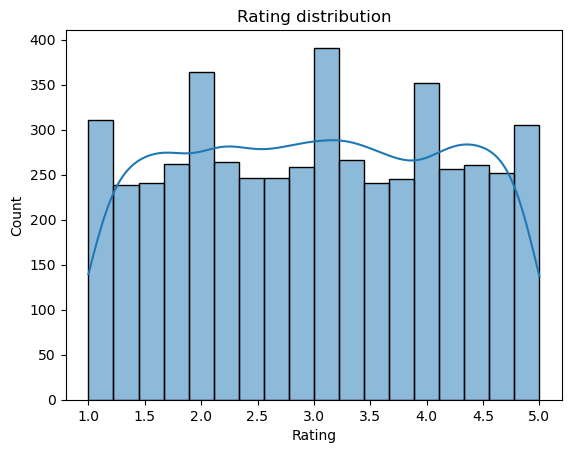

In [157]:
# Univariate Analysis: Numerical
sns.histplot(df['Rating'], kde=True).set_title('Rating distribution')
plt.show()


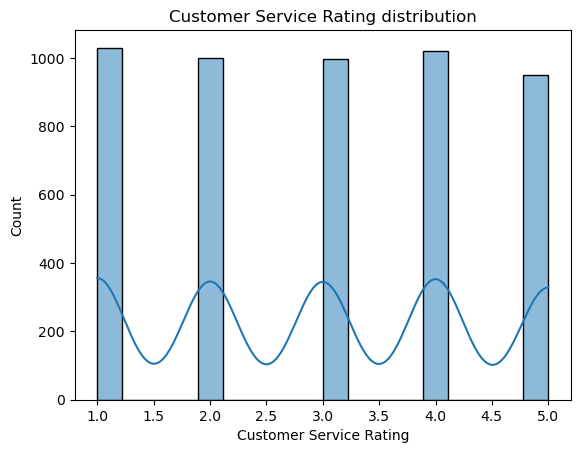

In [159]:
# Univariate Analysis: Numerical
sns.histplot(df['Customer Service Rating'], kde=True).set_title('Customer Service Rating distribution')
plt.show()

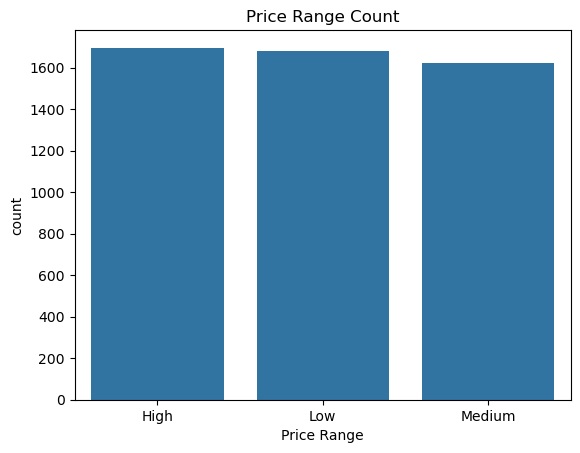

In [161]:
# Univariate Analysis: Categorical
sns.countplot(x='Price Range', data=df).set_title('Price Range Count')
plt.show()

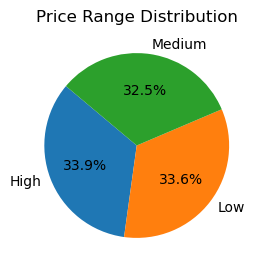

In [163]:
# Univariate Pie Chart: Price Range distribution
gender_counts = df['Price Range'].value_counts()
plt.figure(figsize=(3, 3))
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Price Range Distribution')
plt.show()

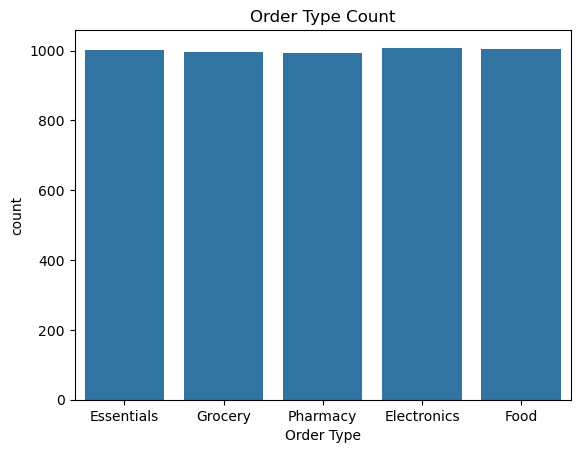

In [165]:
# Univariate Analysis: Categorical
sns.countplot(x='Order Type', data=df).set_title('Order Type Count')
plt.show()

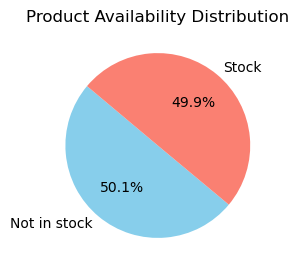

In [167]:
# Univariate Pie Chart: Product Availability distribution
depression_counts = df['Product Availability'].value_counts()
plt.figure(figsize=(3, 3))
plt.pie(depression_counts, labels=['Not in stock', 'Stock'], autopct='%1.1f%%', startangle=140, colors=['skyblue', 'salmon'])
plt.title('Product Availability Distribution')
plt.show()

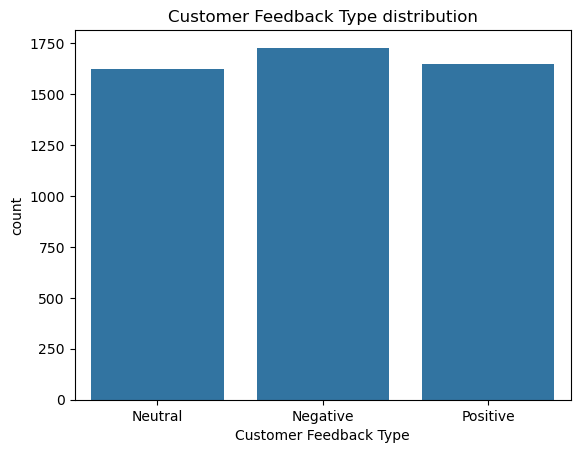

In [169]:
# Univariate Analysis: Categorical
sns.countplot(x='Customer Feedback Type', data=df).set_title('Customer Feedback Type distribution')
plt.show()

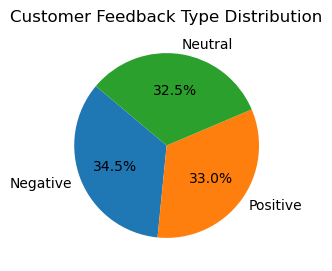

In [171]:
# Univariate Pie Chart:Customer Feedback Type
diet_counts = df['Customer Feedback Type'].value_counts()
plt.figure(figsize=(3, 3))
plt.pie(diet_counts, labels=diet_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Customer Feedback Type Distribution')
plt.show()


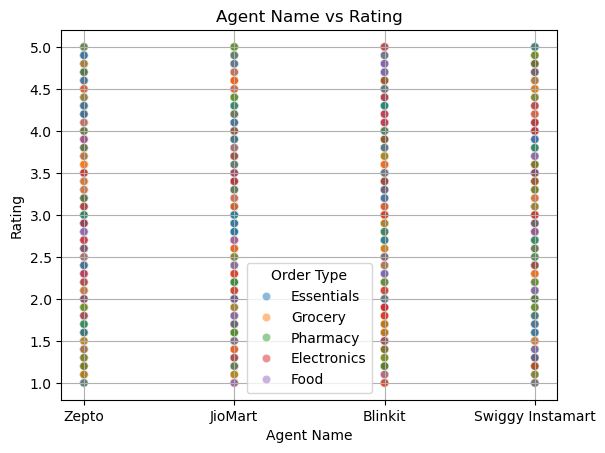

In [173]:
#Agent Name vs Rating by scaatter plot
sns.scatterplot(x='Agent Name', y='Rating',hue='Order Type',  data=df, alpha=0.5)
plt.title('Agent Name vs Rating')
plt.xlabel('Agent Name')
plt.ylabel('Rating')
plt.grid(True)
plt.show()

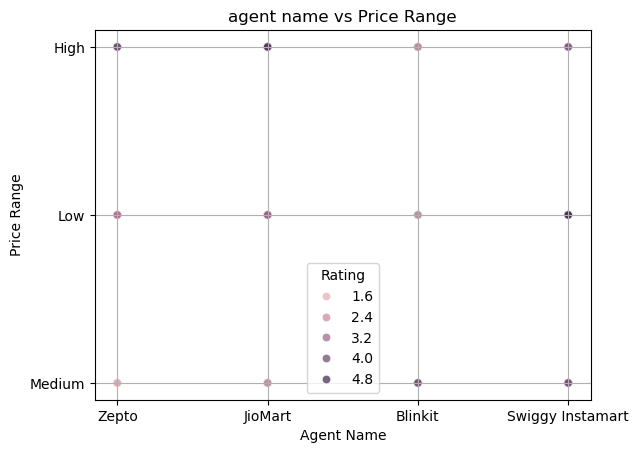

In [174]:
# Scatter plot colored by agent name vs Price Range
sns.scatterplot(x='Agent Name', y='Price Range', hue='Rating', data=df, alpha=0.7)
plt.title('agent name vs Price Range')
plt.xlabel('Agent Name')
plt.ylabel('Price Range')
plt.grid(True)
plt.show()

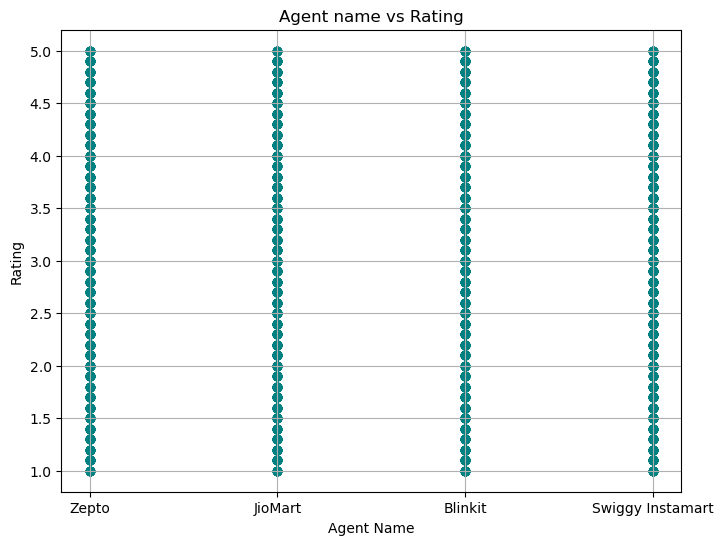

In [176]:
#Agent name vs Rating scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(df['Agent Name'], df['Rating'], color='teal', alpha=0.5)
plt.title('Agent name vs Rating')
plt.xlabel('Agent Name')
plt.ylabel('Rating')
plt.grid(True)
plt.show()